In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

import os
os.environ["PATH"] = "/global/common/software/nersc9/texlive/2024/bin/x86_64-linux:" + os.environ["PATH"]

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = "Times New Roman"

import healpy as hp
import pollux
import pyccl
import scipy.stats
from tqdm.auto import trange

import pickle
import sacc

import re


In [3]:
sim_relative_path = "HACC150_3"
snap_sub_every_n = 4
seed = 0
nside = 8192
sim_root = "/pscratch/sd/d/desc/HOS_Sims/"
save_dir_root = os.path.join(os.environ["CFS"], "lsst/shared/external/HACC-HOS-Y1/HOS_Sims")


In [4]:
dndz_flag="SRDv1_nz"

kappa_dir=dndz_flag
if kappa_dir=="Euclid_dndz_fu08_bin1-5":
    kappa_dir="kappa_"+kappa_dir

reader_dict = dict(
    path=os.path.join(sim_root, sim_relative_path),
    run_params="run/indat.params",
    snap_sub_every_n=snap_sub_every_n,
)
reader = pollux.reader.HACCReader(**reader_dict)
reader_halo = pollux.reader.HACCHaloReader(halo_path="analysis/Halos/b0168/Props", **reader_dict)
cosmo = reader.cosmo

densitymax_z=1.5

builder_dict = dict(
    nside=nside,
    save_dir=os.path.join(
        save_dir_root,
        sim_relative_path,
        f"shells_z{reader.nsnapshots}_subsampledensitymax"+str(densitymax_z)+"_nside"+str(nside)+"/",
    ),
    apply_grid_isometry=True,
    seed=seed,
    subsample_box={"densitymax_z": densitymax_z},
    group_isometries=True,
    dtype=np.float32,
    wsp_dir=save_dir_root,
)

builder = pollux.shells.SnapshotShellBuilder(reader, **builder_dict)
builder_halo = pollux.shells.SnapshotShellBuilder(reader_halo, **builder_dict)

if dndz_flag=="SRDv1_nz":
    dndz = np.loadtxt("data/"+dndz_flag+".txt")
else:
    dndz = np.loadtxt("data/"+dndz_flag+".dat")

lensing_dict_srd = dict(
    nzs=[(dndz[:, 0], dndz[:, i]) for i in range(1, 6)],
    kappa_dir=kappa_dir,
    wsp_dir=save_dir_root,
    sigma_e=0.3,
)
lensing = pollux.lensing.BornLensingBuilder(builder, **lensing_dict_srd)

Cls_th = lensing.predict_cls(auto_only=False,error_bars=True,stacked=True)


*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0xfe1d6d389c60b60f
  - Found 101 snapshots : [ 99 103 107 111 115 119 123 127 131 135 139 143 147 151 155 159 163 167
 171 175 179 183 187 191 195 199 203 207 211 215 219 223 227 231 235 239
 243 247 251 255 259 263 267 271 275 279 283 287 291 295 299 303 307 311
 315 319 323 327 331 335 339 343 347 351 355 359 363 367 371 375 379 383
 387 391 395 399 403 407 411 415 419 423 427 431 435 439 443 447 451 455
 459 463 467 471 475 479 483 487 491 495 499]
  - Subsampling : keeping every 4 snapshots, returns 26 snapshots
*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff   

[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

In [5]:
N_part = 2048

if N_part == 2048:
    sim_list = ["HACC150_3", "HACC195_2"]
    nshells_list = [26, 101]
    seed_list = [0, 1, 2, 3, 4]
elif N_part == 1024:
    sim_list = ["HACC091_1024", "HACC106_1024"]
    nshells_list = [26, 101]
    seed_list = [0]

path = f"subsampledensitymax{densitymax_z}"
extra_info_a = "method\ (1)"

Cls_dict_a = {}

for i_sim in sim_list:
    for i_nshells in nshells_list:
        for i_seed in seed_list:
            fits_file = os.path.join(
                save_dir_root, i_sim, 
                f"shells_z{i_nshells}_{path}_nside{nside}",
                kappa_dir, f"kappa_hacc_seed{i_seed}_nside{nside}_cls.fits"
            )
            
            if not os.path.exists(fits_file):
                print(f"File not found: {fits_file}")
                continue
            
            Cls = {}
            s = sacc.Sacc.load_fits(fits_file)
            
            for t1, t2 in s.get_tracer_combinations():
                ell, cell = np.column_stack([s.get_ell_cl("galaxy_convergence_cl", t1, t2)])
                t1_n = re.search(r'\d+', t1).group()
                t2_n = re.search(r'\d+', t2).group()
                Cls[f"({t1_n}, {t2_n})"] = np.column_stack([ell, cell])

            key = (N_part, i_sim, i_seed, i_nshells, extra_info_a)
            Cls_dict_a[key] = Cls
            print(f"Stored Cls for {key}")


Stored Cls for (2048, 'HACC150_3', 0, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 1, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 2, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 3, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 4, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 0, 101, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 1, 101, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 2, 101, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 3, 101, 'method\\ (1)')
Stored Cls for (2048, 'HACC150_3', 4, 101, 'method\\ (1)')
Stored Cls for (2048, 'HACC195_2', 0, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC195_2', 1, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC195_2', 2, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC195_2', 3, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC195_2', 4, 26, 'method\\ (1)')
Stored Cls for (2048, 'HACC195_2', 0, 101, 'method\\ (1)')
Stored Cls for (2048, 'HACC195_2', 1, 101, 'method\\ (1)')
Stored 

In [6]:
N_part = 2048

if N_part == 2048:
    sim_list = ["HACC150_3", "HACC195_2"]
    nshells_list = [26, 101]
    seed_list = [0, 1, 2, 3, 4]
elif N_part == 1024:
    sim_list = ["HACC091_1024", "HACC106_1024"]
    nshells_list = [26, 101]
    seed_list = [0]

path = f"lightcone_interppollux_subsampledensitymax{densitymax_z}"
extra_info_b = "method\ (2)"

Cls_dict_b = {}

for i_sim in sim_list:
    for i_nshells in nshells_list:
        for i_seed in seed_list:
            fits_file = os.path.join(
                save_dir_root, i_sim, 
                f"shells_z{i_nshells}_{path}_nside{nside}",
                kappa_dir, f"kappa_hacc_seed{i_seed}_nside{nside}_cls.fits"
            )
            
            if not os.path.exists(fits_file):
                print(f"File not found: {fits_file}")
                continue
            
            Cls = {}
            s = sacc.Sacc.load_fits(fits_file)
            
            for t1, t2 in s.get_tracer_combinations():
                ell, cell = np.column_stack([s.get_ell_cl("galaxy_convergence_cl", t1, t2)])
                t1_n = re.search(r'\d+', t1).group()
                t2_n = re.search(r'\d+', t2).group()
                Cls[f"({t1_n}, {t2_n})"] = np.column_stack([ell, cell])
            
            key = (N_part, i_sim, i_seed, i_nshells, extra_info_b)
            Cls_dict_b[key] = Cls
            print(f"Stored Cls for {key}")


Stored Cls for (2048, 'HACC150_3', 0, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC150_3', 1, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC150_3', 2, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC150_3', 3, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC150_3', 4, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC150_3', 0, 101, 'method\\ (2)')
Stored Cls for (2048, 'HACC150_3', 1, 101, 'method\\ (2)')
Stored Cls for (2048, 'HACC150_3', 2, 101, 'method\\ (2)')
Stored Cls for (2048, 'HACC150_3', 3, 101, 'method\\ (2)')
Stored Cls for (2048, 'HACC150_3', 4, 101, 'method\\ (2)')
Stored Cls for (2048, 'HACC195_2', 0, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC195_2', 1, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC195_2', 2, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC195_2', 3, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC195_2', 4, 26, 'method\\ (2)')
Stored Cls for (2048, 'HACC195_2', 0, 101, 'method\\ (2)')
Stored Cls for (2048, 'HACC195_2', 1, 101, 'method\\ (2)')
Stored 

In [7]:
from plots_methods import compute_averages

compute_averages(data_dict=Cls_dict_a, sim_list=sim_list, seed_list=seed_list, nshells_list=nshells_list, N_part=N_part, extra_info=extra_info_a)
compute_averages(data_dict=Cls_dict_b, sim_list=sim_list, seed_list=seed_list, nshells_list=nshells_list, N_part=N_part, extra_info=extra_info_b)

Cls_dict = {**Cls_dict_a, **Cls_dict_b}


Stored avg over seeds for (2048, 'HACC150_3', 'avg', 26, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC150_3', 'std', 26, 'method\\ (1)')
Stored avg over seeds for (2048, 'HACC150_3', 'avg', 101, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC150_3', 'std', 101, 'method\\ (1)')
Stored avg over seeds for (2048, 'HACC195_2', 'avg', 26, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC195_2', 'std', 26, 'method\\ (1)')
Stored avg over seeds for (2048, 'HACC195_2', 'avg', 101, 'method\\ (1)')
Stored std over seeds for (2048, 'HACC195_2', 'std', 101, 'method\\ (1)')

Stored avg over seeds for (2048, 'avg', 'avg', 26, 'method\\ (1)')
Stored std over seeds for (2048, 'std', 'std', 26, 'method\\ (1)')
Stored avg over seeds for (2048, 'avg', 'avg', 101, 'method\\ (1)')
Stored std over seeds for (2048, 'std', 'std', 101, 'method\\ (1)')

Stored avg over seeds for (2048, 'HACC150_3', 'avg', 26, 'method\\ (2)')
Stored std over seeds for (2048, 'HACC150_3', 'std', 26, 'method\\ 

In [8]:
def average_z(zbin):

    return np.trapz(lensing.nzs[zbin][0]*lensing.nzs[zbin][1], lensing.nzs[zbin][0])

def ell_min(zbin):
    
    theta_max = reader.boxsize()/cosmo.comoving_angular_distance(1/(1+average_z(zbin)))
    
    return np.pi/theta_max

ell_min_dict = {zbin: ell_min(zbin) for zbin in range(5)}
    

In [9]:
list_plot = [
    (N_part, "avg", "avg", 26, extra_info_a),
    (N_part, "avg", "avg", 26, extra_info_b),
    (N_part, "avg", "avg", 101, extra_info_a),
    (N_part, "avg", "avg", 101, extra_info_b),
]


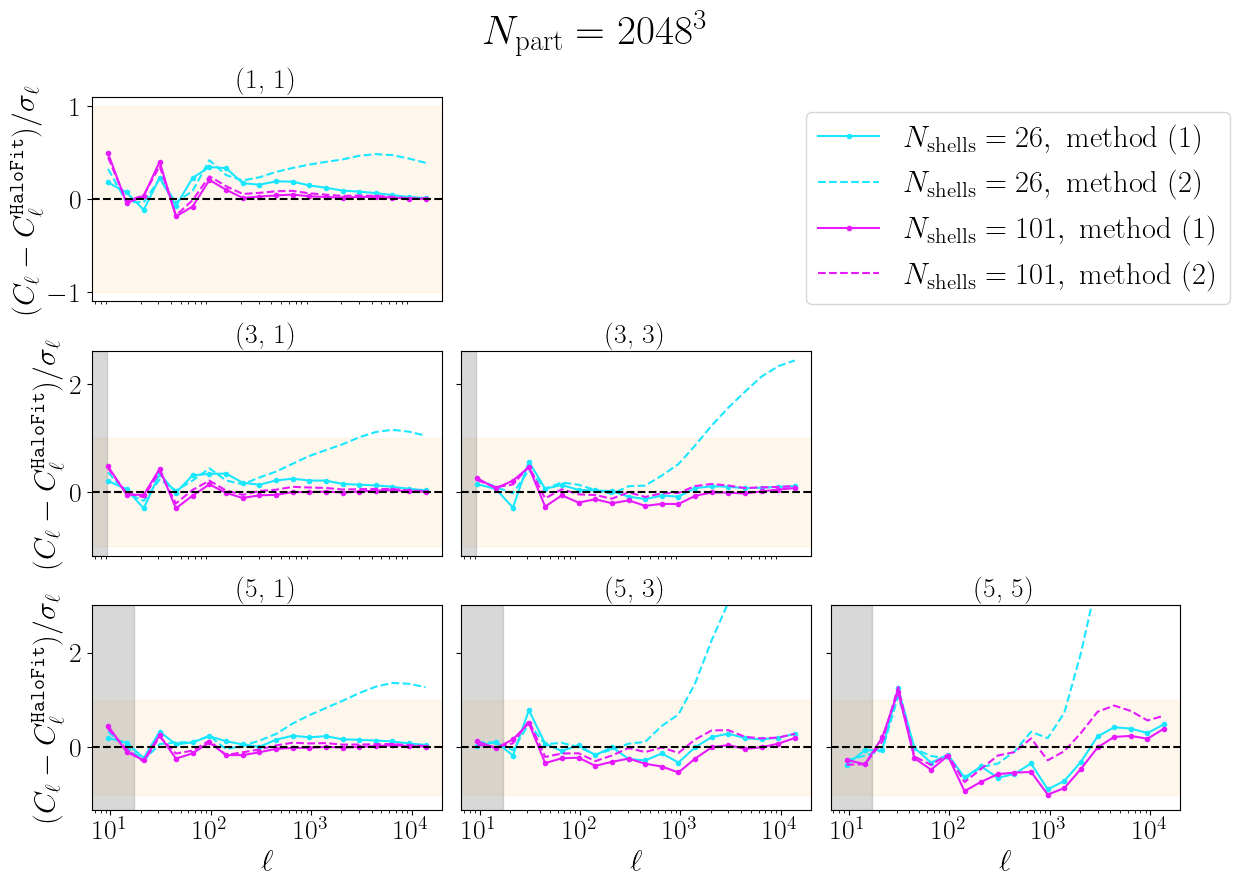

In [10]:
map_list = np.arange(0, 5)
map_list = [0, 2, 4]

from plots_methods import plot_Cls_kappa

# Plot 9
plot_Cls_kappa(9, map_list, Cls_dict, Cls_th, ell_min_dict, list_plot, filename_extra="method1_vs_method2pollux", ylabel=r"$(C_\ell-C_\ell^{\tt HaloFit})/\sigma_\ell$")
